# FrozenLake-v1 Q-Learning Agent Training & Evaluation
Assignment 1 - Topics in AI  (COMSATS University islamabad attock campus)
registration no - fa23-bai-007
name - aftab ahmad
date of submission - 20 october 2026
submitted to - sir salah ud din 

In [4]:
%pip install gymnasium numpy matplotlib

     ------------------------------------ 476.3/476.3 kB 827.8 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import os

# Create Environment
env = gym.make('FrozenLake-v1', is_slippery=True)
print("State Space:", env.observation_space.n)
print("Action Space:", env.action_space.n)

State Space: 16
Action Space: 4


In [6]:
# Hyperparameters
episodes = 10000
alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.001
min_epsilon = 0.01

q_table = np.zeros((env.observation_space.n, env.action_space.n))
rewards_per_episode = []

for episode in range(episodes):
    state, _ = env.reset()
    done = False
    total_reward = 0
    
    while not done:
        # Epsilon-greedy action selection
        if np.random.uniform(0, 1) < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state, :])
            
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        
        # Q-learning update equation
        q_table[state, action] = q_table[state, action] + alpha * (
            reward + gamma * np.max(q_table[next_state, :]) - q_table[state, action]
        )
        
        state = next_state
        total_reward += reward
        
    epsilon = max(min_epsilon, epsilon - epsilon_decay)
    rewards_per_episode.append(total_reward)

# Save Q-table to models folder
os.makedirs("../models", exist_ok=True)
np.save("../models/q_table.npy", q_table)
print("Q-table saved successfully!")

Q-table saved successfully!


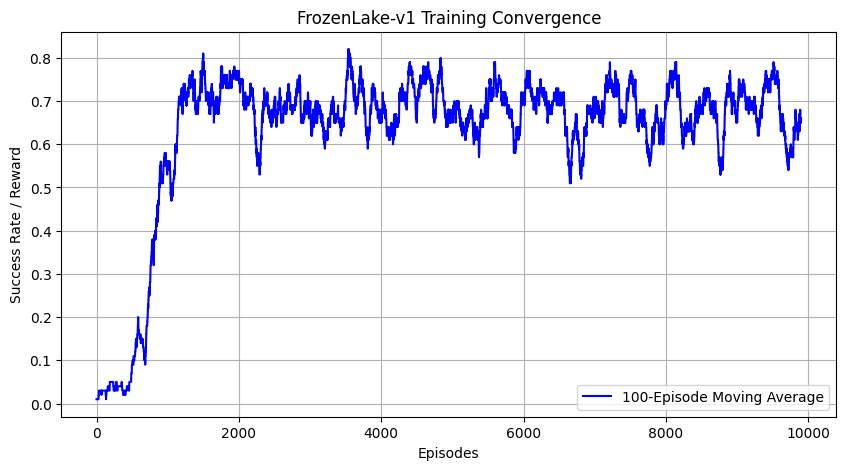

In [7]:
# Plotting 100-episode Moving Average Rewards
moving_avg = np.convolve(rewards_per_episode, np.ones(100)/100, mode='valid')

plt.figure(figsize=(10, 5))
plt.plot(moving_avg, color='blue', label='100-Episode Moving Average')
plt.title('FrozenLake-v1 Training Convergence')
plt.xlabel('Episodes')
plt.ylabel('Success Rate / Reward')
plt.grid(True)
plt.legend()
plt.show()

In [8]:
# Evaluate Agent over 100 Test Episodes
test_episodes = 100
successful_episodes = 0

for _ in range(test_episodes):
    state, _ = env.reset()
    done = False
    
    while not done:
        action = np.argmax(q_table[state, :])
        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        if reward == 1.0:
            successful_episodes += 1

print(f"Evaluation Accuracy / Success Rate: {(successful_episodes / test_episodes) * 100:.2f}%")

Evaluation Accuracy / Success Rate: 81.00%
